# Wadi Ghadir gravity survey – processing chain

**Wadi Ghadir, Eastern Desert, Egypt · Scintrex CG-6 relative gravity · 16–24 January 2026**

**Prepared by Dr. Mohamed Sobh, LIAG** (Leibniz Institute for Applied Geophysics)

This notebook runs the complete gravity processing chain step by step, from the raw CG-6 exports and
GNSS files to the terrain-corrected Bouguer anomalies, the Nettleton density analysis, the maps and the
final result sheets. Every step calls one method of `wghadir.chains.GravityChain`; the numerical work
is done in the `wghadir.gravity` modules, and every tunable value is in `wghadir/gravity/settings.py`.

| Step | Processing | Output tables |
|---:|---|---|
| 1 | Inventory of raw files (SHA-256), CG-6 header metadata | 01, 02 |
| 2 | Verification of the on-board corrections | 03 |
| 3 | Earth tide re-computed (Longman) at the GPS position | 04 |
| 4 | Row-level quality control with explicit thresholds | 05, 06 |
| 5 | Readings grouped into station occupations | 15 |
| 6 | GNSS positions: parsing, datum check, day mapping, matching | 07–09 |
| 7 | EGM2008 orthometric heights, comparison with the Copernicus DEM | 21 |
| 8 | Base-100 control, drift model, daily closures | 10–13 |
| 9 | Inter-instrument scale factor and re-ties | 14 |
| 10 | Free-air and simple Bouguer anomalies (ρ = 2.0–3.0 g/cm³) | 16 |
| 11 | DEM terrain correction (prisms to 22 km), complete Bouguer | 16, 22 |
| 12 | Nettleton density by profile and 3 km window | 17–20, 23 |
| 13 | Summary and deliverables (Excel, CSV, GeoJSON, KML) | `deliverables/` |
| 14 | QC figures, maps, grids, Nettleton sheets | `figures/`, `maps/`, `grids/`, `nettleton/` |

**Run time:** about 1 minute for steps 1–13 and a few minutes for step 14 (400 dpi maps).
On the first run, step 7 downloads the Copernicus GLO-30 DEM and EGM2008 windows (internet needed once);
they are cached in `data/external/`.

All anomalies are **relative to field base 100** because no absolute gravity tie was available.

## 0  Set-up: paths and the chain object

In [1]:
# --- setup -------------------------------------------------------------------------------
# Author: Dr. Mohamed Sobh, LIAG
import os
import sys
import warnings

import numpy as np
import pandas as pd

# make the wghadir package importable when it is not pip-installed (repository layout)
REPO = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
if os.path.abspath(REPO) not in sys.path:
    sys.path.insert(0, os.path.abspath(REPO))

warnings.filterwarnings("ignore", category=FutureWarning)      # verbose third-party deprecation notes
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

from wghadir.common.display import show_figure, show_figures

from wghadir.chains import GravityChain
from wghadir.gravity import settings

RAW_DIR      = os.path.join(REPO, "data", "raw")        # CG-6 .dat, GNSS workbooks/KML as supplied
EXTERNAL_DIR = os.path.join(REPO, "data", "external")   # DEM + geoid cache
OUT_DIR      = os.path.join(REPO, "outputs")            # all results are written here

chain = GravityChain(raw_dir=RAW_DIR, external_dir=EXTERNAL_DIR, out_dir=OUT_DIR)

### Processing settings

These values are used for the delivered products. To change one, edit `wghadir/gravity/settings.py`
and re-run the notebook.

In [2]:
pd.DataFrame(
    [("QC", k, v) for k, v in settings.THRESHOLDS.items()]
    + [("GNSS", n, getattr(settings, n)) for n in ("MATCH_MAX_M", "AMBIG_MARGIN_M", "DISTINCT_LOC_M",
                                                  "BASE_LOC_MAX_M", "DAY_DATUM_SHIFT_MIN_M", "H_SIGMA_NOMINAL_M")]
    + [("Base control", n, getattr(settings, n)) for n in ("TIE_MAX_HOURS", "TARE_MGAL")]
    + [("Terrain", n, getattr(settings, n)) for n in ("COARSE", "INNER_COARSE", "OUTER_RADIUS_M",
                                                     "FLATTEN_RADIUS_M", "SENSOR_OFFSET_M")]
    + [("Reduction", "RHO_LIST", settings.RHO_LIST)],
    columns=["group", "setting", "value"])

,group,setting,value
0,QC,stddev_reject_mgal,0.0800
1,QC,stddev_warn_mgal,0.0500
2,QC,tilt_reject_arcsec,30.0000
3,QC,tilt_warn_arcsec,20.0000
4,QC,repeat_outlier_mgal,0.0500
5,QC,repeat_range_warn_mgal,0.0500
6,QC,gps_spread_warn_m,50.0000
7,QC,gross_range_mgal,500.0000
8,GNSS,MATCH_MAX_M,30.0000
9,GNSS,AMBIG_MARGIN_M,10.0000


## 1  Inventory and instrument metadata

Both CG-6 exports (`#0640` new instrument, `#0313` old instrument) are read completely; every raw file is
listed with its size and SHA-256 checksum so the input can be traced. The CG-6 header gives the instrument
constants (calibration, drift settings) used on board.

In [3]:
files = chain.step01_inventory()
display(files)
chain.meta

[1] 1519 readings from 2 instruments


,file,bytes,sha256
0,Astra_processing_prompt.md,7738,38f1733ea251b9c2dff227af0a784a3bb5caf42b962b77...
1,CG-6_0313_W_GHADER_old_gravimeter.dat,129588,c4ee0ba3059fbf1636ec01c5986c716b0f4266a52ba928...
2,CG-6_0640_W_GHADIR_New_gravimeter.dat,138508,5495ae79b0678a593811457464db9c1f33978f82fd78b5...
3,GPS_All_Days.xlsx,59581,cfaf07bce7d119613f4e56fc03b89290ab58ca1bc9ed48...
4,results.zip,186531,06ec74fc322b36b94a6653b4159e26c284d8b2a7444470...


,instrument,file,bytes,sha256,survey_name,serial,created,operator,firmware,gcal1_mgal,goff_adu,gref_mgal,x_scale,y_scale,x_offset,y_offset,temp_coeff_mgal_per_mK,temp_scale,drift_rate_mgal_per_day,drift_zero_time,rows,first_reading,last_reading,survey_days,lines,correction_flags,measur_dur_s,instr_height_m,user_lat_lon_elev,columns
0,CG6-0640,CG-6_0640_W_GHADIR_New_gravimeter.dat,138508,5495ae79b0678a593811457464db9c1f33978f82fd78b5...,W_GHADIR,000000024110640,2026-01-16 03:52:49,NRIAG,CG6_2_20240409,8323.669000,-8388608.000000,0.0000,0.045429,0.045020,-13170.328680,-27997.357409,-0.126000,-0.000111,0.000000,2024-07-17 18:55:52,795,2026-01-16 03:52:49,2026-01-24 17:41:21,9,"0,1",11011,60,0.0,25.327812/34.625248/149.4,Station|Date|Time|CorrGrav|Line|StdDev|StdErr|...
1,CG6-0313,CG-6_0313_W_GHADER_old_gravimeter.dat,129588,c4ee0ba3059fbf1636ec01c5986c716b0f4266a52ba928...,W_GHADER,000000021010313,2026-01-16 03:54:27,NRIAG,CG6_2_20240409,7869.544000,-8388608.000000,8000.0000,0.030278,0.030363,-223096.498266,-149814.641486,-0.133000,-0.000111,0.397500,2020-12-16 17:41:32,724,2026-01-16 03:54:27,2026-01-24 17:58:32,9,"0,2,3,4,5,6,7,8,9,10,11,12,13,14,15",11011,60,0.0,43.79/-79.50354/209.07,Station|Date|Time|CorrGrav|Line|StdDev|StdErr|...


## 2  Verification of the on-board corrections

The CG-6 stores `CorrGrav = RawGrav + TideCorr + TiltCorr + TempCorr + DriftCorr`. The closure of this
sum is checked for every row; it closes within 0.2 µGal (rounding of the export), so each term can be
replaced individually in the next steps.

In [4]:
chain.step02_verify_onboard_corrections()

[2] CorrGrav closure rms [mGal]: CG6-0313 6.7e-05, CG6-0640 6.5e-05


,instrument,rows_checked,rows_with_overflow,closure_rms_mgal,closure_max_abs_mgal,equation,mean_tide,mean_temp,mean_tilt,mean_drift
0,CG6-0313,724,1,0.0001,0.0002,CorrGrav = RawGrav + TideCorr + TiltCorr + Tem...,-0.0213,0.2706,0.0007,-739.6295
1,CG6-0640,795,2,0.0001,0.0002,CorrGrav = RawGrav + TideCorr + TiltCorr + Tem...,-0.0042,0.4929,0.0010,0.0000


## 3  Earth tide

The on-board tide (Longman 1959) is reproduced to < 1 µGal when evaluated at the **user-entered position
with the time stamps as UTC**. For #0313 the user position was left at Toronto (43.79° N, 79.50° W), so the
tide is re-computed at the CG-6 GPS position for both instruments: `g_tidefix = CorrGrav − TideCorr + tide(GPS)`.
The table also shows that shifting the time by ±2–3 h does not fit, which confirms the UTC time base.

In [5]:
tide = chain.step03_recompute_tide()
tide

[3] tide re-computed (Longman, UTC, GPS position)


,instrument,model,rms_ugal,max_abs_ugal
0,CG6-0313,"Longman at user-entered position, t as UTC",0.2083,0.4199
1,CG6-0313,"Longman at CG-6 GPS position, t as UTC",89.6351,215.0771
2,CG6-0313,"Longman at user position, t shifted -3 h",73.8532,134.1670
3,CG6-0313,"Longman at user position, t shifted -2 h",50.3093,92.8440
4,CG6-0313,"Longman at user position, t shifted +2 h",48.7447,93.2889
5,CG6-0313,"Longman at user position, t shifted +3 h",68.2619,134.5982
6,CG6-0640,"Longman at user-entered position, t as UTC",0.1937,0.4333
7,CG6-0640,"Longman at CG-6 GPS position, t as UTC",1.8306,3.1151
8,CG6-0640,"Longman at user position, t shifted -3 h",70.0431,152.4953
9,CG6-0640,"Longman at user position, t shifted -2 h",49.9987,98.9306


## 4  Row-level quality control

Every reading is kept and receives an explicit accept/reject decision with reasons:

* overflow fields (`******`) in the export; frozen sensor output of #0313 (RawGrav 8007.5–8009.0 mGal);
* gross range: |g − instrument median| > 500 mGal;
* StdDev > 0.080 mGal (reject) / > 0.050 mGal (warning);
* tilt max(|X|, |Y|) > 30″ (reject) / > 20″ (warning);
* repeat outlier: > 0.050 mGal from the median of the other readings of the occupation (n ≥ 3).

The sensitivity table shows how many rows and complete occupations other thresholds would remove.

In [6]:
reasons = chain.step04_row_qc()
display(reasons.rename("rejected rows").to_frame())
chain.qc_sensitivity.pivot_table(index=["metric", "threshold"], columns="instrument",
                                 values=["rows_rejected", "occupations_lost"])

[4] accepted 1472 of 1519 readings


,rejected rows
reject_reasons,
FROZEN_SENSOR_OUTPUT,27
REPEAT_OUTLIER,8
STDDEV_GT_0.080,4
TILT_GT_30,3
OVERFLOW_FIELD;GROSS_RANGE_GT_500;TILT_GT_30,2
GROSS_RANGE_GT_500,1
GROSS_RANGE_GT_500;TILT_GT_30,1
OVERFLOW_FIELD,1


occupations_lost          rows_rejected         
instrument                              CG6-0313 CG6-0640      CG6-0313 CG6-0640
metric                threshold                                                 
StdDev [mGal]         0.0300             92.0000 117.0000      139.0000 137.0000
                      0.0400             36.0000  71.0000       62.0000  81.0000
                      0.0500             16.0000  31.0000       33.0000  37.0000
                      0.0600              4.0000  15.0000       14.0000  19.0000
                      0.0800              0.0000   4.0000        0.0000   4.0000
                      0.1000              0.0000   1.0000        0.0000   1.0000
max(|X|,|Y|) [arcsec] 10.0000            85.0000 186.0000      133.0000 255.0000
                      15.0000             5.0000  46.0000       15.0000  80.0000
                      20.0000             1.0000  12.0000        6.0000  19.0000
                      25.0000             0.0000   6.0000        1.0000   6.0000
                      30.0000             0.0000   3.0000        1.0000   3.0000
                      40.0000             0.0000   2.0000        0.0000   2.0000

## 5  Station occupations

Readings of one instrument at one line/station on one date, with gaps < 15 min, form an occupation.
Its value is the mean of the accepted readings; its uncertainty is the larger of the internal standard
error and the scatter of the repeats.

In [7]:
occ = chain.step05_occupations()
display(occ.groupby(["instrument", "role"]).agg(occupations=("occ_id", "size"), usable=("usable", "sum")))
occ[["occ_key", "n_readings", "n_accepted", "g_occ", "sigma_occ", "occ_flags"]].head(10)

[5] 1116 occupations, 1094 usable


occupations  usable
instrument role                               
CG6-0313   field                   466     457
           field_base_100           29      26
           hotel_base_0             18      16
CG6-0640   field                   559     551
           field_base_100           26      26
           hotel_base_0             18      18

,occ_key,n_readings,n_accepted,g_occ,sigma_occ,occ_flags
0,CG6-0313|2026-01-16|L0|S0,4,4,9409.4002,0.0033,
1,CG6-0313|2026-01-16|L0|S100,4,4,9344.0795,0.0032,
2,CG6-0313|2026-01-16|L0|S100,4,4,9344.6373,0.0027,
3,CG6-0313|2026-01-16|L2|S1,2,2,9343.9682,0.0236,
4,CG6-0313|2026-01-16|L2|S2,2,2,9343.6791,0.0107,
5,CG6-0313|2026-01-16|L2|S3,2,2,9343.1175,0.0018,
6,CG6-0313|2026-01-16|L2|S4,2,2,9342.3987,0.0120,
7,CG6-0313|2026-01-16|L2|S5,2,2,9341.8865,0.0062,
8,CG6-0313|2026-01-16|L2|S6,2,2,9341.5527,0.0063,
9,CG6-0313|2026-01-16|L2|S7,2,2,9340.9908,0.0017,


## 6  GNSS positions and station matching

The GNSS point workbooks (DMS coordinates) and the KML files are parsed. GNSS days are mapped to the
gravity dates **by coordinates**, the daily datum is checked at the two base marks (day 7 heights are
2.83 m too high and are lowered), and every occupation is matched to one GNSS point:

* nearest GNSS point of the same day within 30 m of the CG-6 internal GPS position;
* ambiguous if a second, distinct location (> 5 m away) lies within the nearest distance + 10 m;
  ambiguity is resolved only when the station ID identifies one candidate.

In [8]:
status = chain.step06_gnss_positioning()
display(status.pivot(index="match_status", columns="instrument", values="n").fillna(0).astype(int))
chain.datum_days

[6] 1031 GNSS points; occupations matched: 1092


instrument,CG6-0313,CG6-0640
match_status,,
MATCHED,505,577
MATCHED_ID_TIEBREAK,5,5
UNMATCHED_GT_30M,3,21


,gnss_day,dh_hotel0_m,dh_base100_m,day_height_shift_m,day_shift_sigma_m,rule,mrsa_h,mrsa_E_local,mrsa_N_local
0,1,0.1040,0.1150,0.0000,0.0000,no adjustment,48.9861,0.0000,0.0000
1,2,-0.0240,0.0220,0.0000,0.0000,no adjustment,48.8610,2.3500,-0.7610
2,3,0.0260,-0.0030,0.0000,0.0000,no adjustment,48.8830,2.3500,-0.7610
3,4,0.0000,-0.2020,0.0000,0.0000,no adjustment,48.8680,2.3500,-0.7610
4,5,-0.0180,-0.0160,0.0000,0.0000,no adjustment,48.8680,2.3500,-0.7610
5,6,0.0550,-0.2670,0.0000,0.0000,no adjustment,48.8680,2.3500,-0.7610
6,7,2.5090,3.1550,2.8320,0.3230,both base marks offset > 0.5 m with equal sign...,48.8680,2.3500,-0.7610
7,8,-0.0020,0.0000,0.0000,0.0000,no adjustment,48.8680,2.3500,-0.7610
8,9,-0.0110,0.0411,0.0000,0.0000,no adjustment,48.8680,2.3500,-0.7610


## 7  Heights: EGM2008 and the Copernicus DEM

The GNSS heights are ellipsoidal: h − DEM = +12.1 m, the same as the EGM2008 undulation N ≈ 12.3 m.
Orthometric heights are therefore `H = h − N` (EGM2008), consistent with the Copernicus GLO-30 DEM
(EGM2008 heights). The table shows the comparison per GNSS day.

In [9]:
chain.step07_heights_and_dem()

[7] median H - DEM = -0.29 m


,gnss_day,n,median_h_ellip_minus_dem,median_H_minus_dem,mad_H_minus_dem,day_shift_applied,median_N_egm2008,median_H_minus_dem_without_day_shift
0,1,118,11.8133,-0.0831,0.3865,0.0000,11.9496,-0.0831
1,2,90,12.0889,-0.0900,0.3492,0.0000,12.2419,-0.0900
2,3,116,12.4022,-0.0409,0.1793,0.0000,12.4293,-0.0409
3,4,75,12.0152,-0.4428,0.3788,0.0000,12.4819,-0.4428
4,5,121,12.3418,-0.2354,0.3420,0.0000,12.5646,-0.2354
5,6,63,11.0692,-1.1961,0.9877,0.0000,12.3882,-1.1961
6,7,144,14.3014,-0.8171,0.6008,2.8320,12.4256,2.0149
7,8,175,11.9185,-0.1645,0.3031,0.0000,12.2216,-0.1645
8,9,99,11.7558,-0.5674,0.4990,0.0000,12.2801,-0.5674


## 8  Base control and drift model

Station 100 on line 0 is the field control. For each instrument the drift is modelled piecewise linearly
between successive base-100 occupations; station 0 (hotel) adds supplementary control through the median
hotel–base-100 tie. The model uncertainty comes from leave-one-out misclosures; base-100 jumps > 0.3 mGal are
treated as tares.

In [10]:
closures = chain.step08_base_control()
display(pd.Series(chain.model_sigma, name="drift-model sigma [mGal]").to_frame())
closures

[8] drift-model sigma per instrument [mGal]: {'CG6-0313': 0.05317580030054999, 'CG6-0640': 0.007847312848655953}


,drift-model sigma [mGal]
CG6-0313,0.0532
CG6-0640,0.0078


,instrument,date,n_base100_occupations,n_base100_valid,hotel_closure_mgal,hotel_closure_hours,base100_first_last_mgal,base100_span_hours,base100_range_mgal,base100_first_value,base100_first_time
0,CG6-0313,2026-01-16,5,5,0.4582,14.0278,0.4641,8.9146,0.5579,9344.0795,2026-01-16 06:10:06
1,CG6-0313,2026-01-17,3,3,-0.1508,9.4086,0.0793,5.6339,0.1098,9344.1580,2026-01-17 09:08:51
2,CG6-0313,2026-01-18,3,2,NaN,NaN,-0.1380,4.0864,0.1380,9343.7995,2026-01-18 06:13:53
3,CG6-0313,2026-01-19,2,2,NaN,NaN,-0.0519,4.1075,0.0519,9343.8334,2026-01-19 09:04:00
4,CG6-0313,2026-01-20,3,2,-0.3414,12.1244,-0.1588,3.4928,0.1588,9343.3287,2026-01-20 11:39:38
5,CG6-0313,2026-01-21,3,3,-0.1144,10.5883,-0.0637,7.4086,0.1270,9342.8228,2026-01-21 07:32:01
6,CG6-0313,2026-01-22,3,3,-0.1366,13.2017,-0.1093,8.1192,0.1093,9342.1633,2026-01-22 07:26:56
7,CG6-0313,2026-01-23,3,3,-0.4053,13.5753,-0.1360,9.0036,0.1786,9341.8521,2026-01-23 06:31:18
8,CG6-0313,2026-01-24,4,3,-0.2432,12.9108,-0.2440,9.5921,0.2440,9341.5333,2026-01-24 06:44:06
9,CG6-0640,2026-01-16,5,5,0.0062,14.0394,0.0038,7.8336,0.0108,3407.0210,2026-01-16 06:09:20


## 9  Inter-instrument reconciliation

The scale of #0313 relative to #0640 is estimated independently from the hotel–base-100 ties and from
co-located field points. Both agree within 2σ, so their inverse-variance weighted mean is applied to all
#0313 values. #0313 segments extrapolated beyond a base control are re-tied to co-located #0640 values.

In [11]:
scale = chain.step09_instrument_reconciliation()
display(scale.to_frame("value"))
chain.retie

[9] scale factor applied to CG-6 #0313: k = 1.011892568547996


,value
k_tie,1.0117
k_tie_se,0.0003
tie_0640,"{'n': 18, 'median': -66.07364238809419, 'mean'..."
tie_0313,"{'n': 15, 'median': -65.32431237204037, 'mean'..."
k_colocated,1.0127
k_colocated_se,0.0007
offset_colocated,-0.0344
offset_colocated_se,0.0230
colocated_n,3
colocated_rms_mgal,0.0146


,date,n_pairs,offset_mgal,offset_sd_mgal,applied
0,2026-01-18,5,-0.2253,0.0223,True


## 10  Free-air and simple Bouguer anomalies

Relative to base 100 (subscript 100), with WGS84 normal gravity γ and the second-order free-air term FA(H):

* ΔFA = Δg₁₀₀ − [γ(φ) − γ(φ₁₀₀)] + [FA(H) − FA(H₁₀₀)]
* ΔSB(ρ) = ΔFA − 0.04193 ρ (H − H₁₀₀), for ρ = 2.0 … 3.0 g/cm³

In [12]:
st = chain.step10_reductions()
s = st[st["product_ok"]]
s[["dg100_scaled_mgal", "H_ortho_m", "dFA_rel_mgal", "dSB_rel_rho2.67_mgal", "dFA_sigma_mgal"]].describe()

[10] 985 stations with complete products


,dg100_scaled_mgal,H_ortho_m,dFA_rel_mgal,dSB_rel_rho2.67_mgal,dFA_sigma_mgal
count,985.0000,985.0000,985.0000,985.0000,985.0000
mean,-33.6433,272.1503,20.8592,1.5740,0.0661
std,24.5375,106.2763,11.3381,5.0742,0.0235
min,-94.3728,2.2318,-14.8096,-14.5719,0.0470
25%,-46.3913,220.1309,18.3946,-1.1917,0.0470
50%,-32.5305,281.6082,24.9354,2.5965,0.0706
75%,-16.6866,337.9118,28.0702,5.6770,0.0710
max,18.2516,489.5301,36.8218,9.8881,0.1222


## 11  Terrain correction and complete Bouguer anomaly

The Copernicus GLO-30 DEM is converted into right-rectangular prisms around each station (Harmonica):
1″ cells within ±2 km, 8 × 8 block-averaged cells out to 22 km, Earth curvature included, DEM flattened to the
station height within 50 m, sensor 0.2 m above the GNSS point. For density ρ:

* ΔCB(ρ) = ΔFA − ρ [g₁(station) − g₁(base 100)],  g₁ = topographic attraction for 1 g/cm³
* TC(ρ) = ρ (0.04193 H − g₁)  (terrain + curvature correction relative to the slab)

The validation table shows how much g₁ changes with finer zoning, a 20 km radius and +0.5 m station height.

In [13]:
tval = chain.step11_terrain_correction()
s = chain.st[chain.st["product_ok"]]
display(s[["TC_rho2.67_mgal", "dCB_rel_rho2.67_mgal"]].describe())
tval

  terrain: 0/985 stations


  terrain: 200/985 stations


  terrain: 400/985 stations


  terrain: 600/985 stations


  terrain: 800/985 stations


[11] terrain correction done in 21 s


,TC_rho2.67_mgal,dCB_rel_rho2.67_mgal
count,985.0000,985.0000
mean,0.9424,1.3930
std,0.3789,4.9014
min,0.2096,-13.9529
25%,0.6902,-1.2033
50%,0.8823,2.2585
75%,1.1557,5.4522
max,2.7789,9.4176


,occ_key,TC1,g1,d_finer_outer_and_wider_inner,d_outer_radius_20km,d_station_height_plus_0_5m
0,CG6-0640|2026-01-16|L1|S1,0.0785,0.0151,-0.0003,0.0030,0.0213
1,CG6-0640|2026-01-23|L1|S471,0.1834,12.9592,-0.0007,-0.0067,0.0231
2,CG6-0313|2026-01-16|L3|S24,0.2276,10.5736,-0.0007,-0.0027,0.0245
3,CG6-0640|2026-01-18|L1|S148,0.2643,13.9361,-0.0012,-0.0073,0.0221
4,CG6-0640|2026-01-22|L1|S362,0.2885,14.1211,-0.0010,-0.0085,0.0231
5,CG6-0313|2026-01-16|L2|S3,0.3176,4.2855,-0.0006,0.0024,0.0264
6,CG6-0313|2026-01-19|L7|S7,0.3416,9.7299,-0.0006,-0.0002,0.0270
7,CG6-0640|2026-01-16|L1|S43,0.3708,3.8360,-0.0006,0.0028,0.0261
8,CG6-0640|2026-01-20|L1|S260,0.4204,16.2630,-0.0019,-0.0140,0.0223
9,CG6-0313|2026-01-16|L3|S4,0.4737,7.5832,-0.0007,0.0010,0.0289


## 12  Reduction density: Nettleton method

Continuous traverses are cut into profiles. For each profile the density is estimated (i) as the density at
which the detrended Bouguer anomaly is uncorrelated with the detrended topography and (ii) by the regression
ΔFA = a + b·x + ρ·u, with a block bootstrap for the uncertainty — both for the slab (simple) and the DEM
(complete) Bouguer effect u. Moving 3 km windows and a χ² consensus summarise the estimates.

In [14]:
consensus = chain.step12_density_nettleton()
display(consensus)
chain.net[["profile_id", "method", "n_used", "rho_zero_corr", "rho_regression", "rho_regression_se",
           "relief_m", "length_km"]].head(12)

[12] 28 profiles, 102 windows


,set,method,n,weighted_mean,weighted_se,median,p25,p75,chi2,dof,p_value,birge_ratio,weighted_se_scaled
0,profiles,simple,15,2.3000,0.0407,2.9268,1.6398,3.1818,1483.4019,14,0.0000,10.2936,0.4185
1,profiles,complete,19,2.5226,0.0318,2.0390,1.3607,2.9265,964.4973,18,0.0000,7.3201,0.2325
2,3km_windows,simple,16,3.0526,0.0766,3.1489,2.1023,3.4312,57.4492,15,0.0000,1.9570,0.1499
3,3km_windows,complete,32,2.7865,0.0444,2.5294,1.5716,3.0170,179.9484,31,0.0000,2.4093,0.1069


,profile_id,method,n_used,rho_zero_corr,rho_regression,rho_regression_se,relief_m,length_km
0,N-L1-1-148,simple,147,2.8711,2.8711,2.0370,336.4380,30.3788
1,N-L1-1-148,complete,147,2.4944,0.7756,0.8799,336.4380,30.3788
2,N-L1-149-225,simple,76,NaN,-1.1357,0.1234,237.4095,17.2062
3,N-L1-149-225,complete,76,NaN,-1.2033,0.1552,237.4095,17.2062
4,N-L1-226-245,simple,20,NaN,3.6432,0.8217,68.8047,4.4283
5,N-L1-226-245,complete,20,2.3758,2.0390,0.5122,68.8047,4.4283
6,N-L1-246-300,simple,54,NaN,-2.0418,0.3268,88.6815,10.3161
7,N-L1-246-300,complete,54,NaN,-2.5501,0.3910,88.6815,10.3161
8,N-L1-301-335,simple,22,3.0077,3.0077,0.2846,77.7973,5.1935
9,N-L1-301-335,complete,22,2.9942,2.9550,0.2934,77.7973,5.1935


## 13  Summary and deliverables

`deliverables/Wadi_Ghadir_Gravity_Results.xlsx` holds the final station sheet (FA, SB and CB for all
densities, coordinates in WGS84 and UTM 36N), a column dictionary and all QC sheets. The same table is
written as CSV, GeoJSON (GIS) and KML (Google Earth).

In [15]:
final = chain.step13_summary_and_export()
display(sorted(os.listdir(chain.deliverable_dir)))
final.head()

[13] deliverables written to ../outputs/deliverables


['Wadi_Ghadir_Final_Stations.csv',
 'Wadi_Ghadir_Final_Stations.geojson',
 'Wadi_Ghadir_Final_Stations.kml',
 'Wadi_Ghadir_Gravity_Results.xlsx',
 'Wadi_Ghadir_Magnetic_Results.xlsx']

,Station_UID,Instrument,Date,Line,Station,GNSS_Point,GNSS_Source,Match_Dist_m,Lat_deg,Lon_deg,UTM36N_E_m,UTM36N_N_m,Time_UTC,N_Readings,h_ellip_m,N_EGM2008_m,H_ortho_m,H_DEM_m,H_minus_DEM_m,dH_rel_base100_m,...,SB_rel_2.80_mGal,SB_rel_2.90_mGal,SB_rel_3.00_mGal,CB_rel_2.00_mGal,CB_rel_2.20_mGal,CB_rel_2.30_mGal,CB_rel_2.40_mGal,CB_rel_2.50_mGal,CB_rel_2.60_mGal,CB_rel_2.67_mGal,CB_rel_2.70_mGal,CB_rel_2.80_mGal,CB_rel_2.90_mGal,CB_rel_3.00_mGal,Dist_to_Sea_km,Drift_Mode,Scale_k_applied,Day_Height_Shift_m,Match_Status,QC_Warnings
0,CG6-0313|2026-01-16|L2|S1,CG6-0313,2026-01-16,2,1,2-1,results.zip/day1.xlsx,4.9202,24.7848,34.9343,695550.7575,2742501.0146,2026-01-16 07:14:27,2,115.1460,11.8802,103.2658,108.3694,-5.1036,3.3768,...,0.1135,0.0994,0.0852,0.3266,0.3082,0.2990,0.2899,0.2807,0.2715,0.2651,0.2624,0.2532,0.2440,0.2348,7.7974,INTERPOLATED,1.0119,0.0000,MATCHED,
1,CG6-0313|2026-01-16|L2|S2,CG6-0313,2026-01-16,2,2,2-2,results.zip/day1.xlsx,4.2803,24.7828,34.9340,695528.1019,2742276.3146,2026-01-16 07:21:03,2,119.2940,11.8834,107.4106,107.9117,-0.5011,7.5216,...,0.7560,0.7244,0.6929,0.7751,0.6887,0.6455,0.6023,0.5591,0.5159,0.4856,0.4727,0.4295,0.3863,0.3431,7.9353,INTERPOLATED,1.0119,0.0000,MATCHED,
2,CG6-0313|2026-01-16|L2|S3,CG6-0313,2026-01-16,2,3,2-3,results.zip/day1.xlsx,2.0765,24.7832,34.9324,695364.4299,2742325.8288,2026-01-16 07:26:30,2,121.6700,11.8911,109.7789,109.9163,-0.1374,9.8900,...,0.6111,0.5696,0.5282,0.7365,0.6329,0.5811,0.5293,0.4775,0.4258,0.3895,0.3740,0.3222,0.2704,0.2186,8.0477,INTERPOLATED,1.0119,0.0000,MATCHED,
3,CG6-0313|2026-01-16|L2|S4,CG6-0313,2026-01-16,2,4,2-4,results.zip/day1.xlsx,1.9369,24.7835,34.9305,695171.8389,2742358.1481,2026-01-16 07:32:39,2,126.3060,11.9003,114.4057,113.9968,0.4088,14.5167,...,0.7499,0.6890,0.6281,0.9139,0.7599,0.6829,0.6059,0.5289,0.4519,0.3980,0.3748,0.2978,0.2208,0.1438,8.1895,INTERPOLATED,1.0119,0.0000,MATCHED,
4,CG6-0313|2026-01-16|L2|S5,CG6-0313,2026-01-16,2,5,2-5,results.zip/day1.xlsx,0.9603,24.7824,34.9289,695008.6470,2742234.7859,2026-01-16 07:37:49,2,129.5860,11.9095,117.6765,117.2257,0.4507,17.7875,...,0.9347,0.8601,0.7855,1.1858,1.0021,0.9103,0.8184,0.7265,0.6347,0.5704,0.5428,0.4510,0.3591,0.2673,8.3941,INTERPOLATED,1.0119,0.0000,MATCHED,


## 14  Figures, maps and grids

Writes the QC figures (`figures/`), the 400 dpi maps (`maps/`), the grids as NetCDF and XYZ CSV (`grids/`)
and one Nettleton sheet per profile (`nettleton/`). Gridding: UTM 36N, 200 m block median, damped
biharmonic spline on a 100 m grid, blanked > 2 km from the stations; the block K-fold cross-validation error
of each grid is returned below. This step takes a few minutes.

In [16]:
cv = chain.step14_figures_and_maps()
pd.Series(cv, name="cross-validation rms [mGal]").to_frame()

  maps ...


  Nettleton figures ...


[14] figures in ../outputs/figures, maps, nettleton; grids in ../outputs/grids


,cross-validation rms [mGal]
dg100_scaled_mgal,1.8337
dFA_rel_mgal,1.1611
dSB_rel_rho2.67_mgal,0.6500
dCB_rel_rho2.67_mgal,0.6443


### Quality-control figures

`fig01_coverage_map.png`

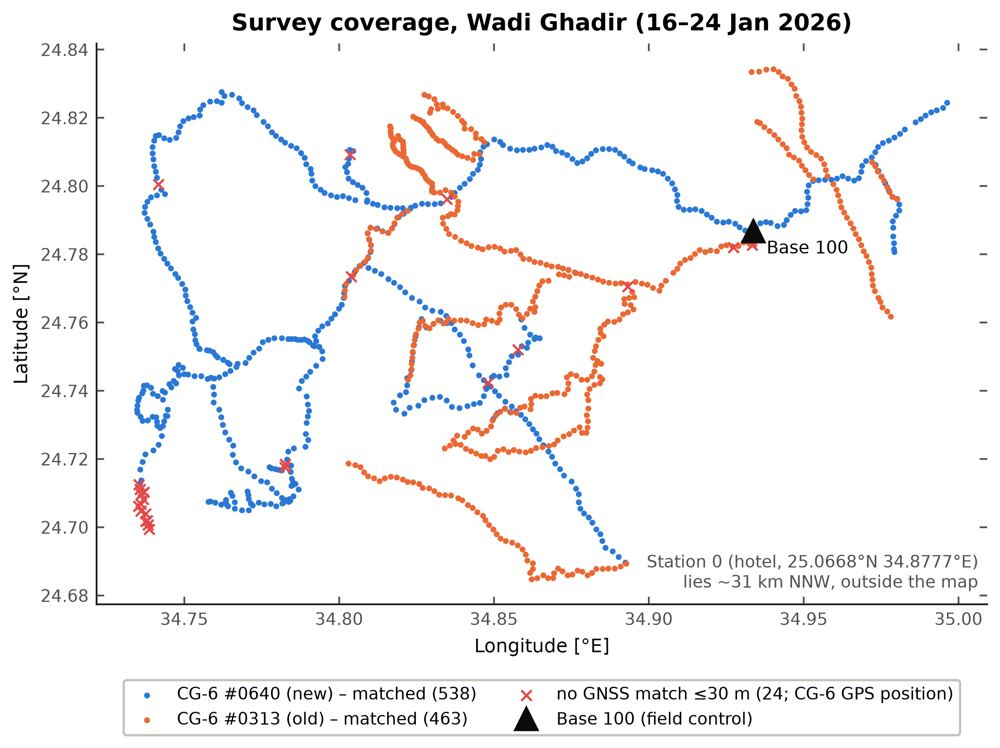

`fig02_tide_check.png`

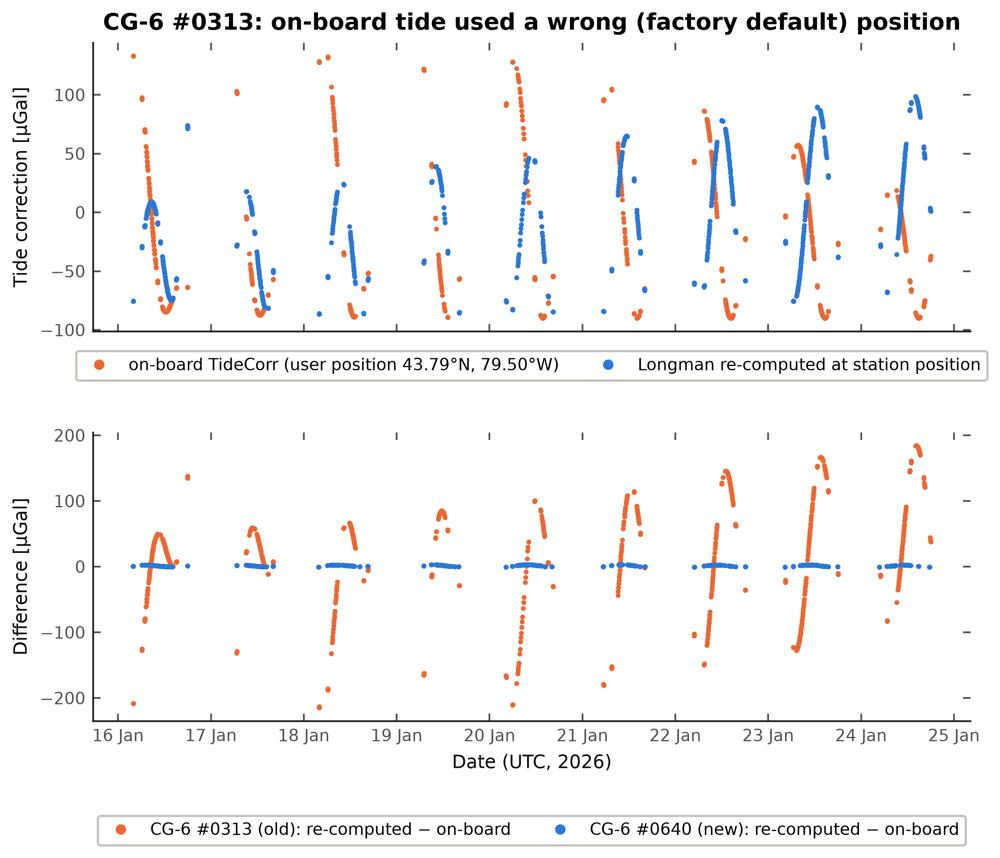

`fig03_correction_terms.png`

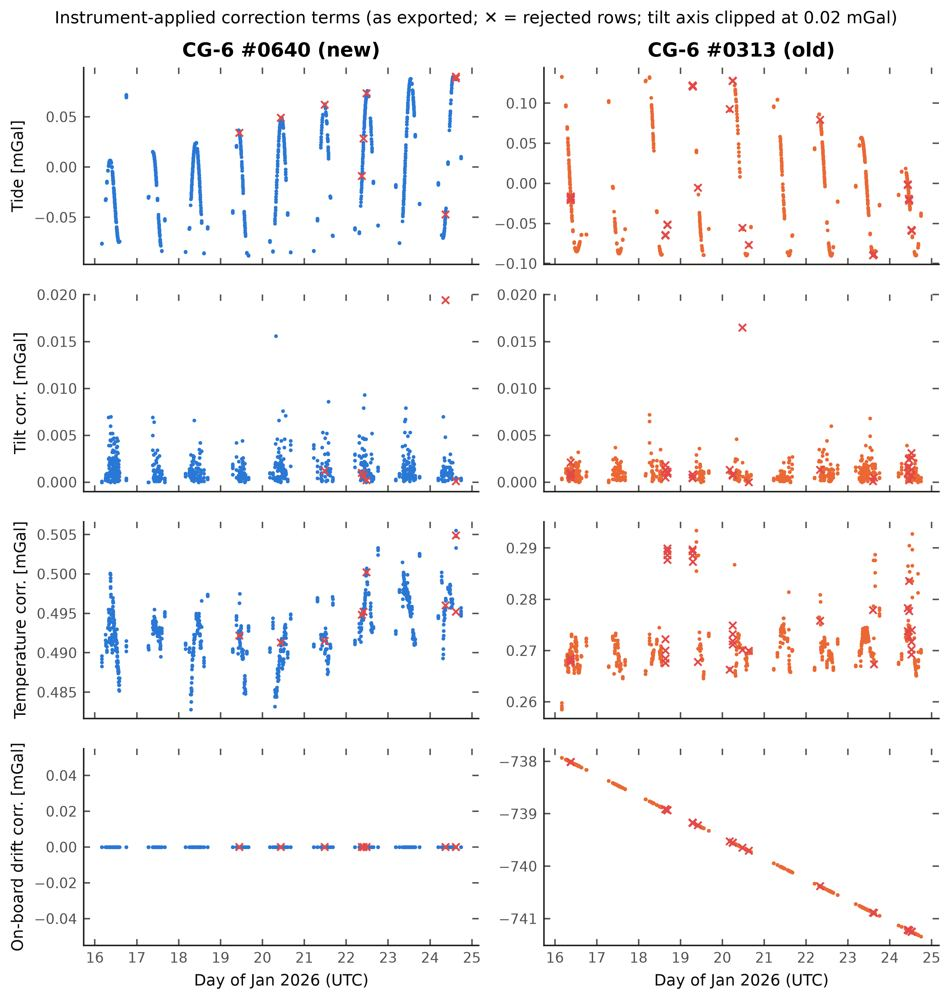

`fig04_reading_timeseries.png`

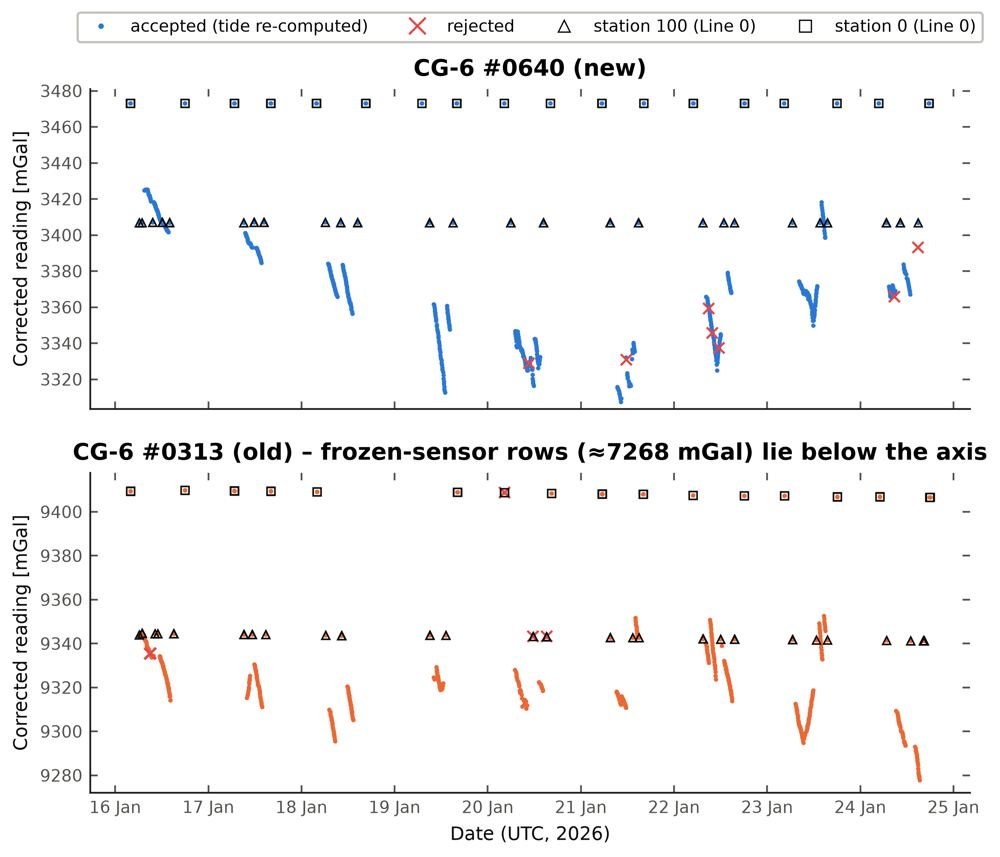

`fig05_qc_stddev_tilt.png`

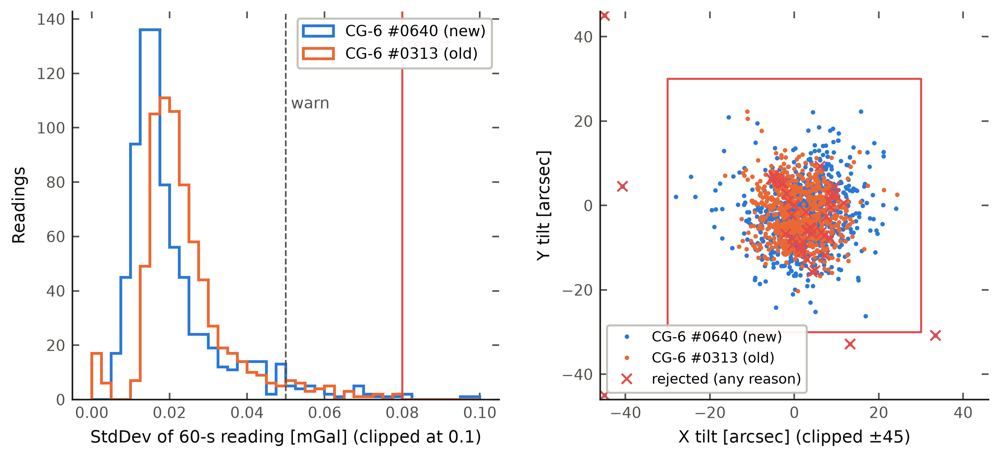

`fig06_base100_daily.png`

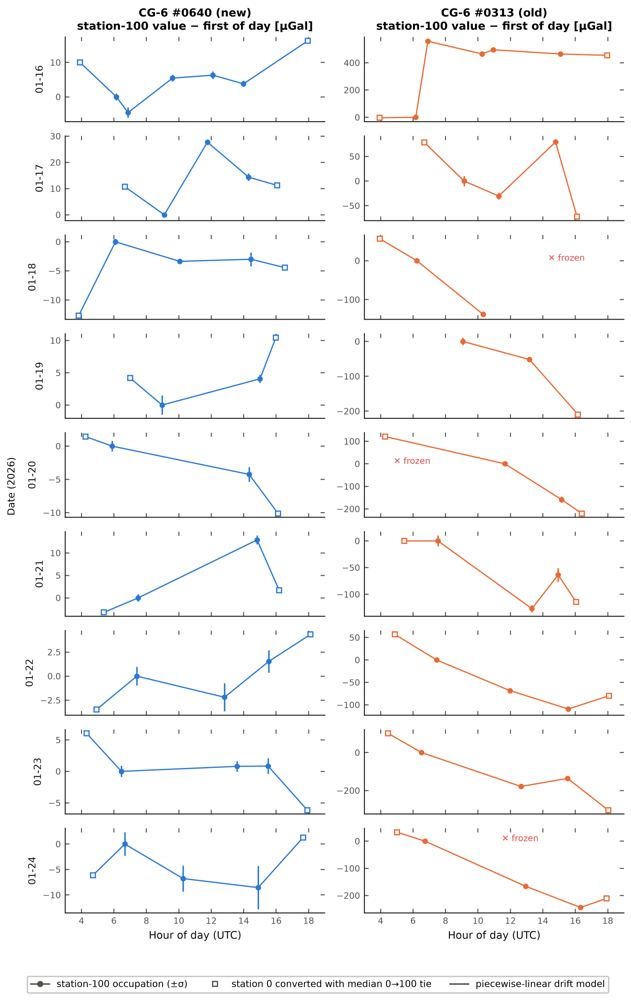

`fig07_ties_and_closures.png`

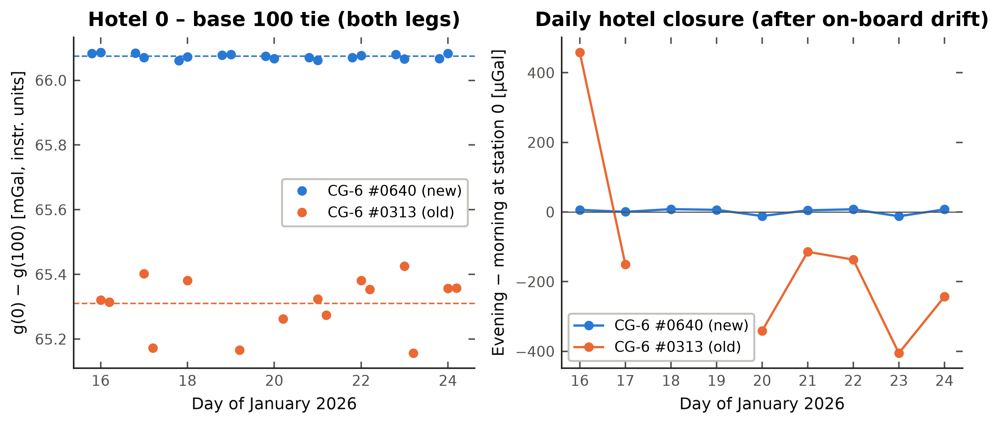

`fig08_instrument_comparison.png`

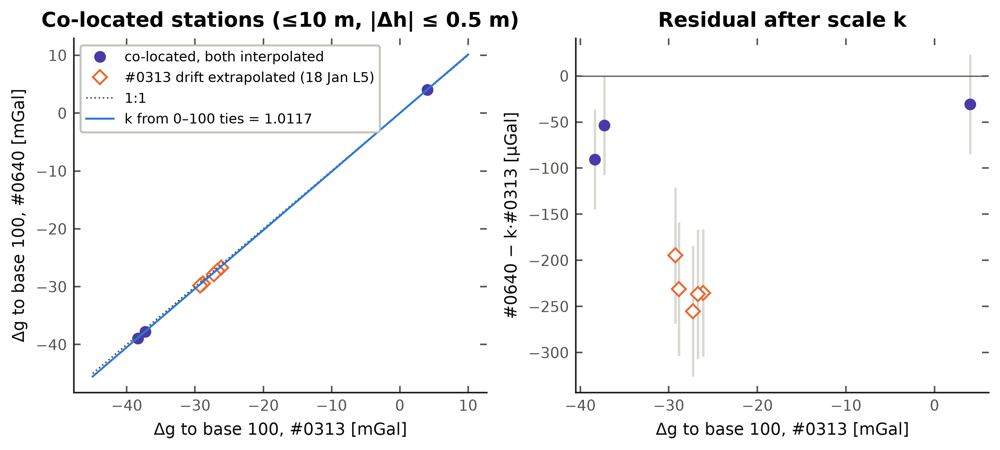

`fig09_gnss_checks.png`

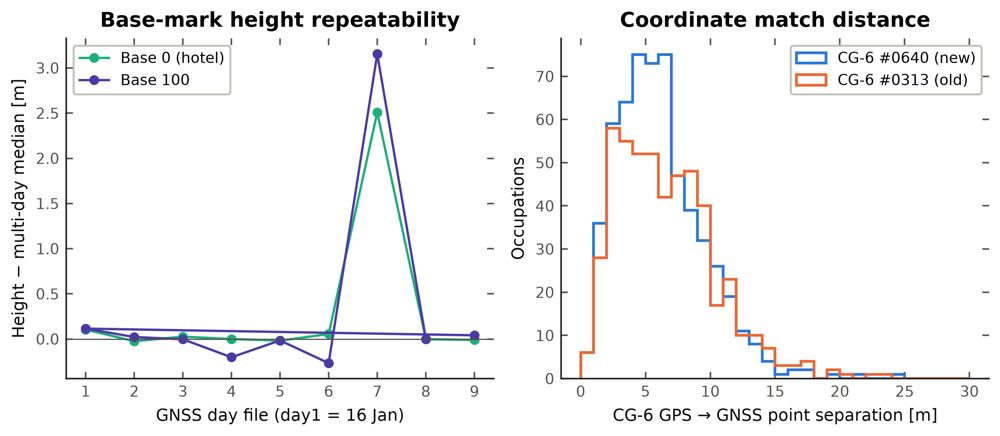

In [17]:
show_figures(os.path.join(OUT_DIR, "figures"), max_px=1000)

### Maps: stations, heights, observed gravity, free-air, Bouguer and terrain correction

`map01_station_distribution.png`

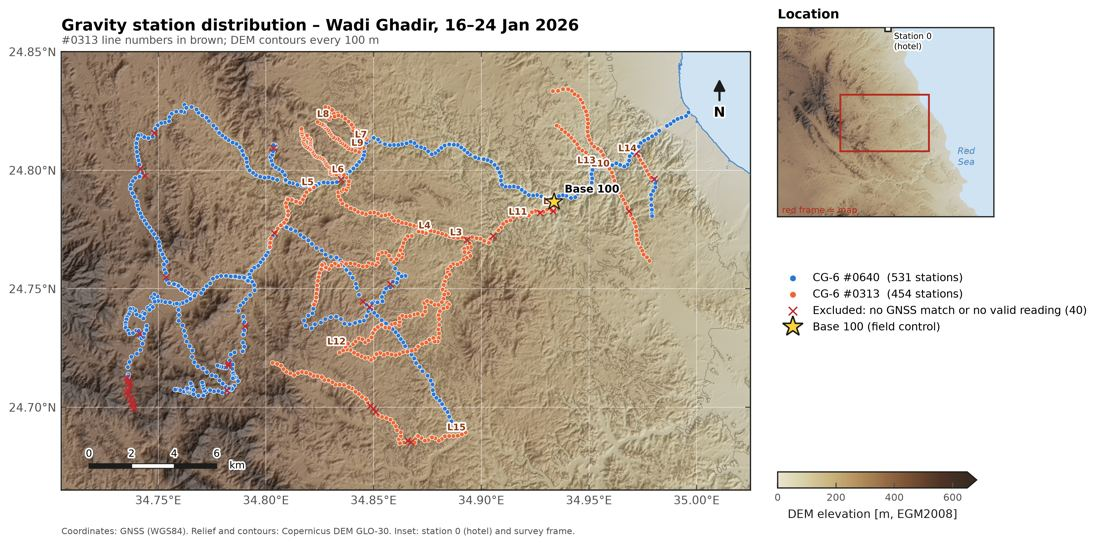

`map02_station_elevation.png`

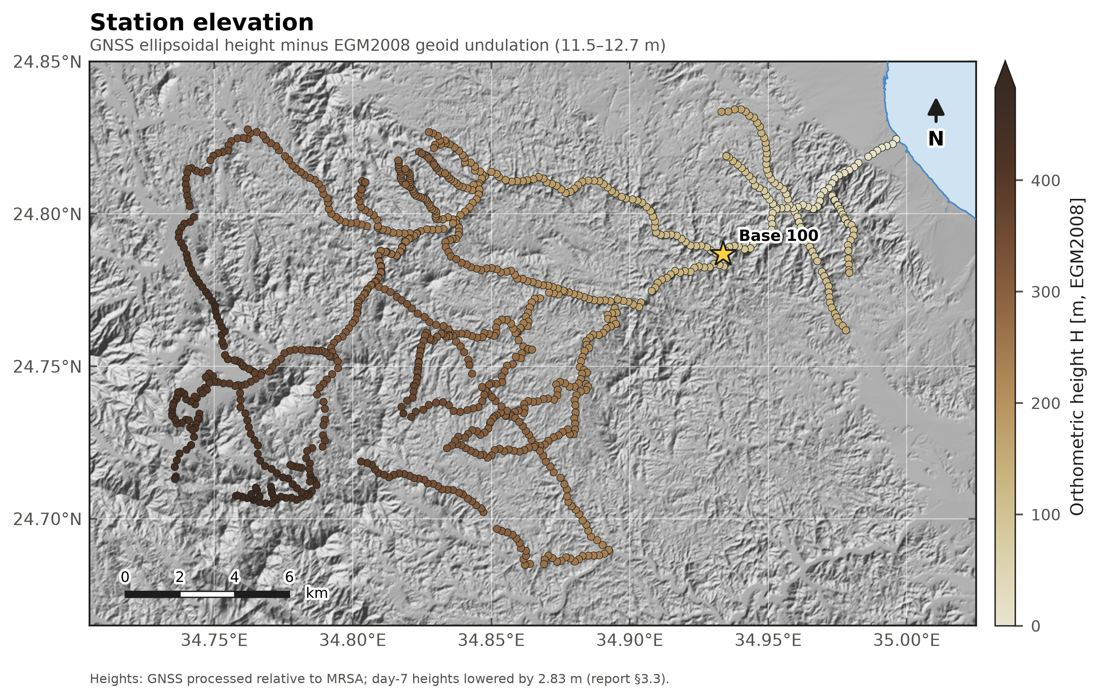

`map03_height_check_vs_dem.png`

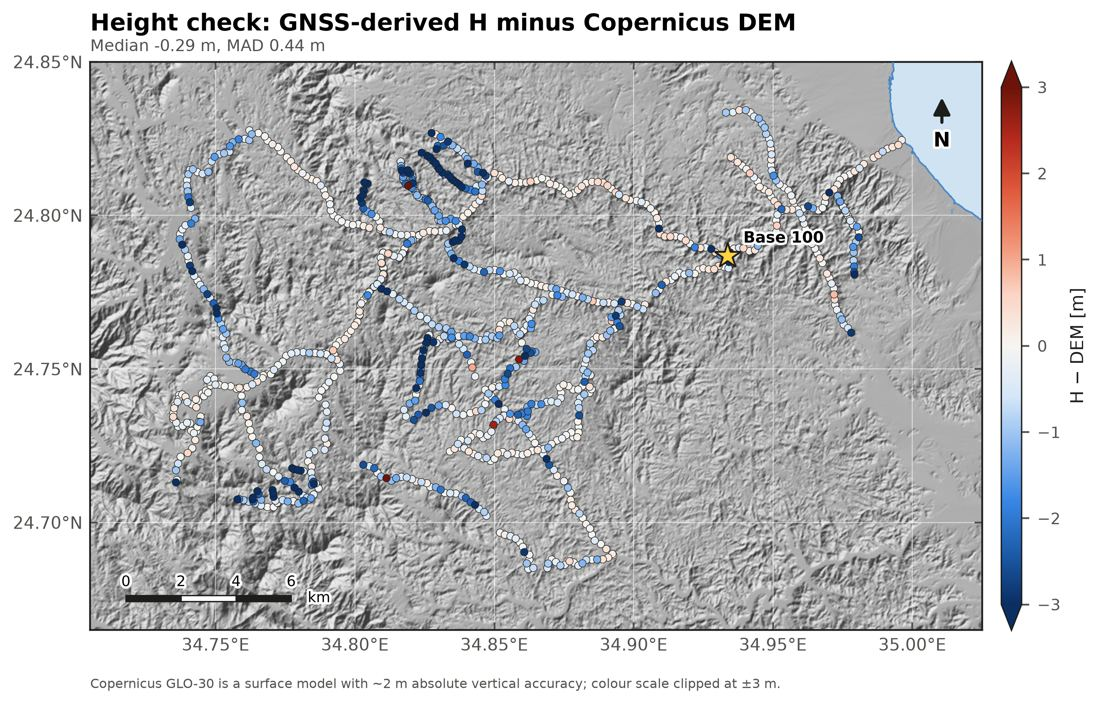

`map04_station_uncertainty.png`

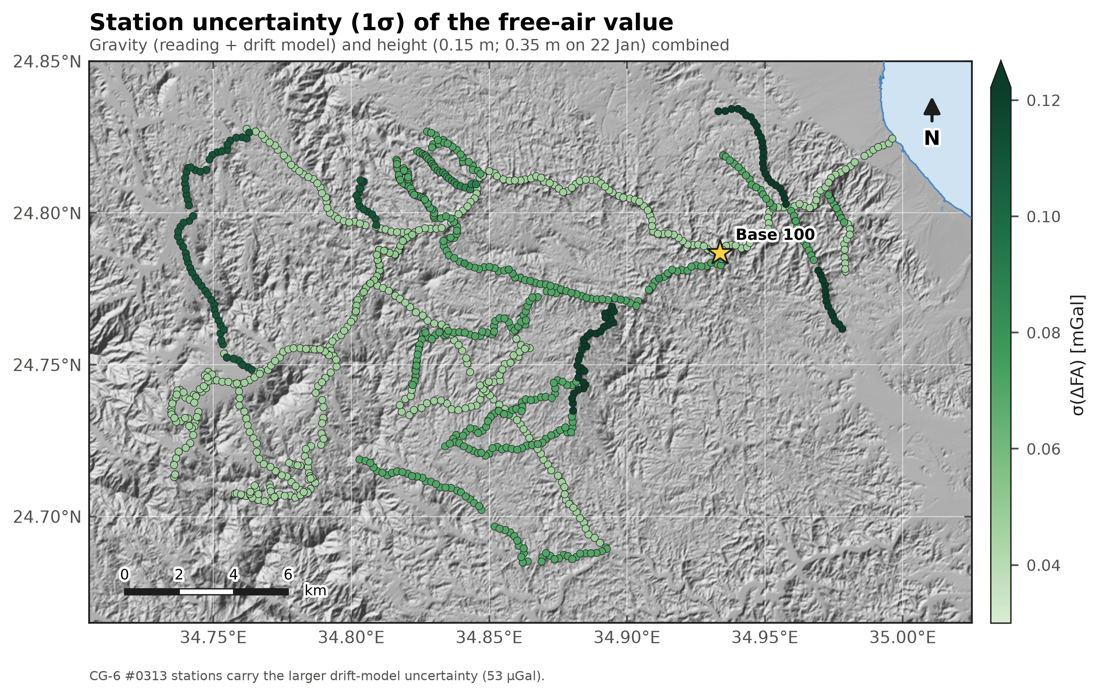

`map05_observed_gravity.png`

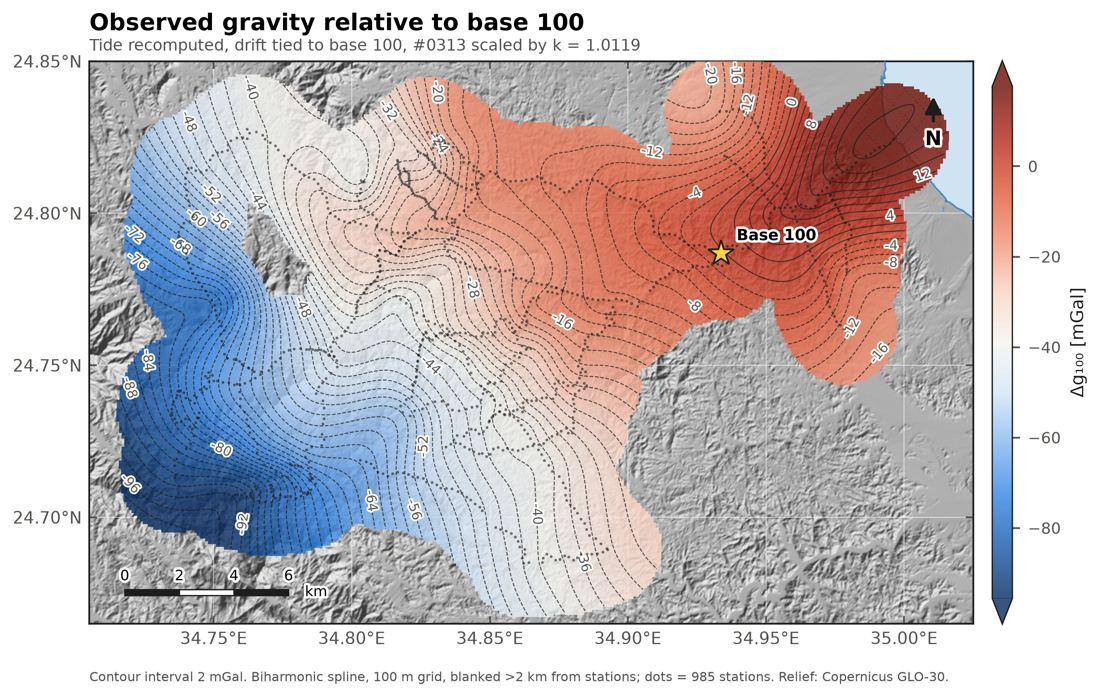

`map06_free_air_anomaly.png`

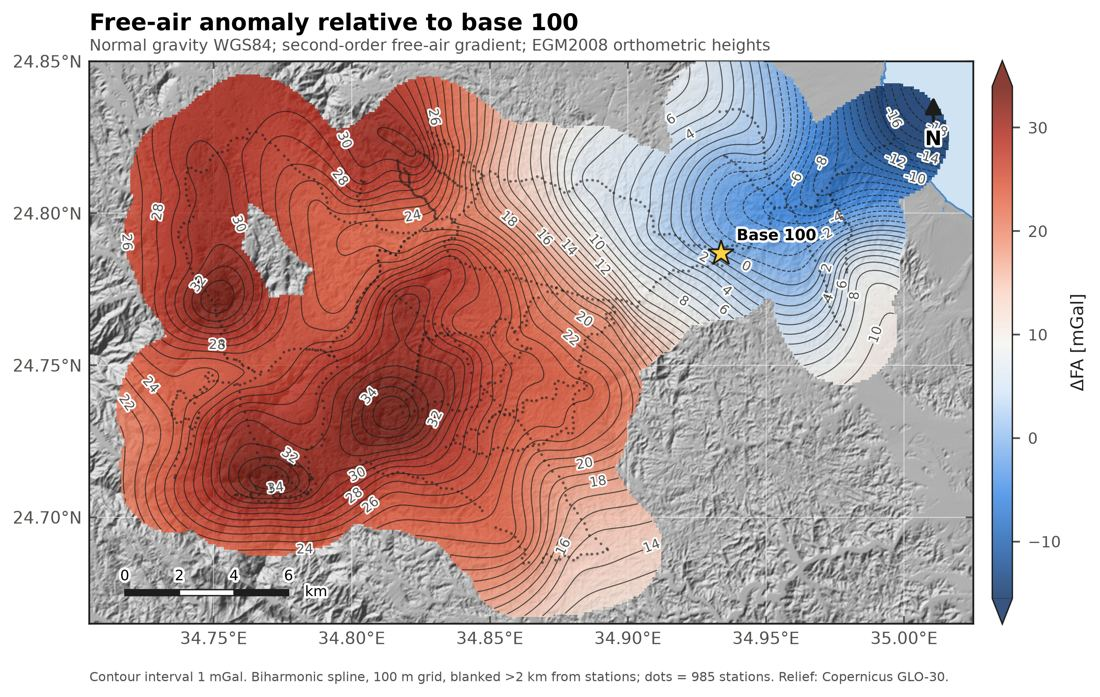

`map07_simple_bouguer_2.67.png`

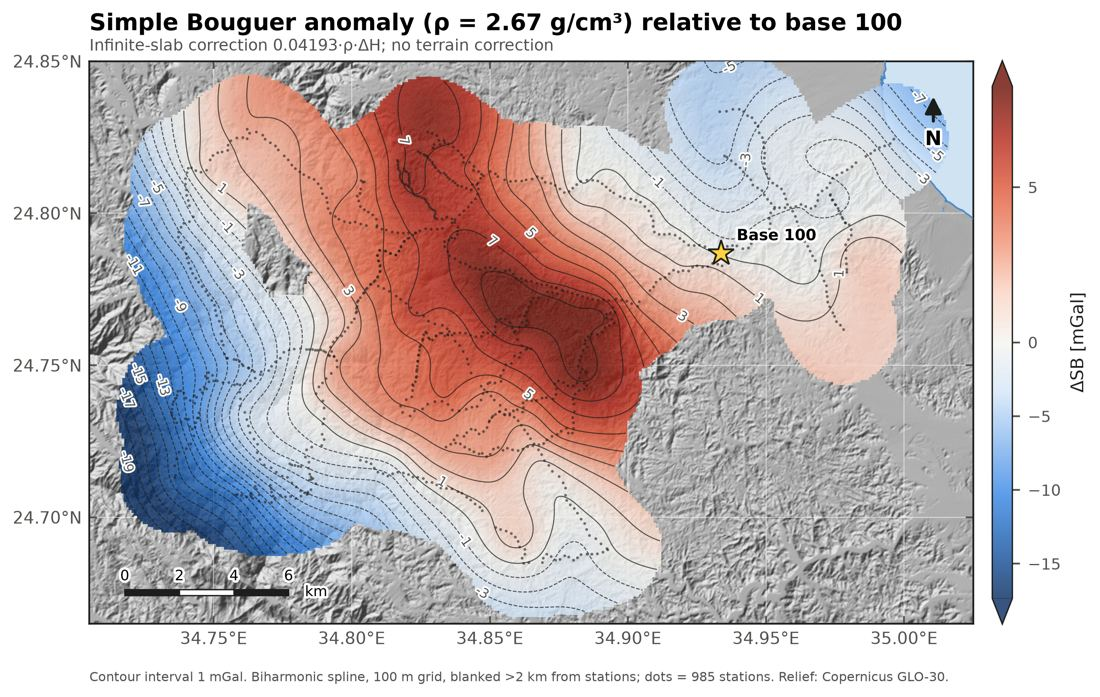

`map08_terrain_correction_2.67.png`

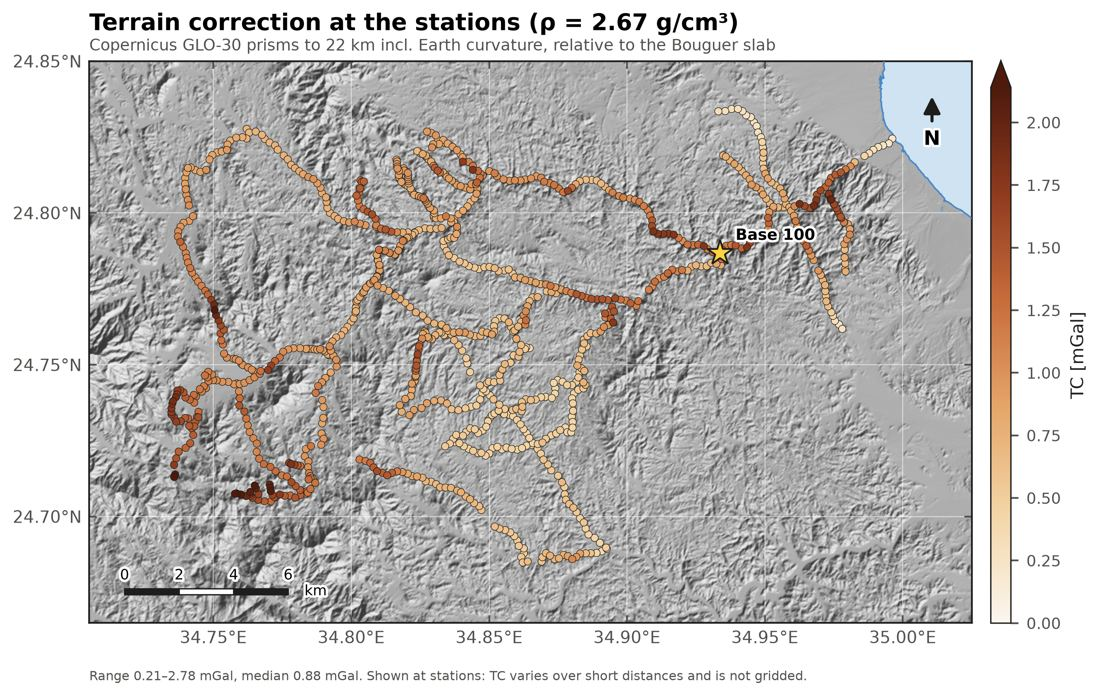

`map09_complete_bouguer_2.67.png`

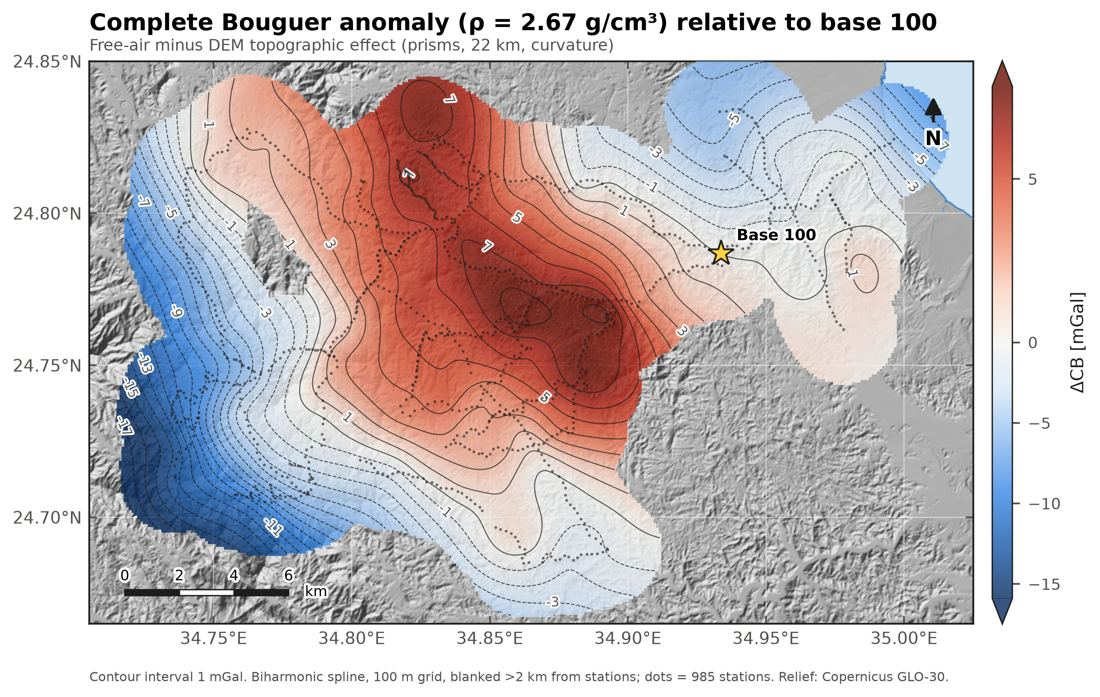

`map10_complete_bouguer_density_panel.png`

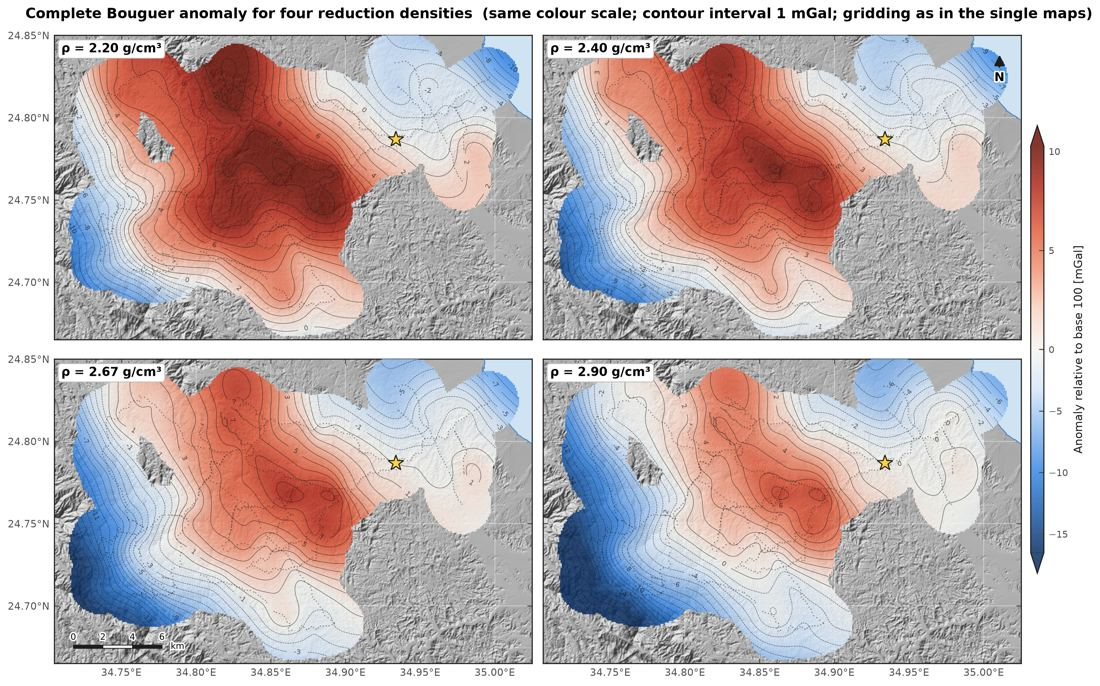

`map11_simple_bouguer_density_panel.png`

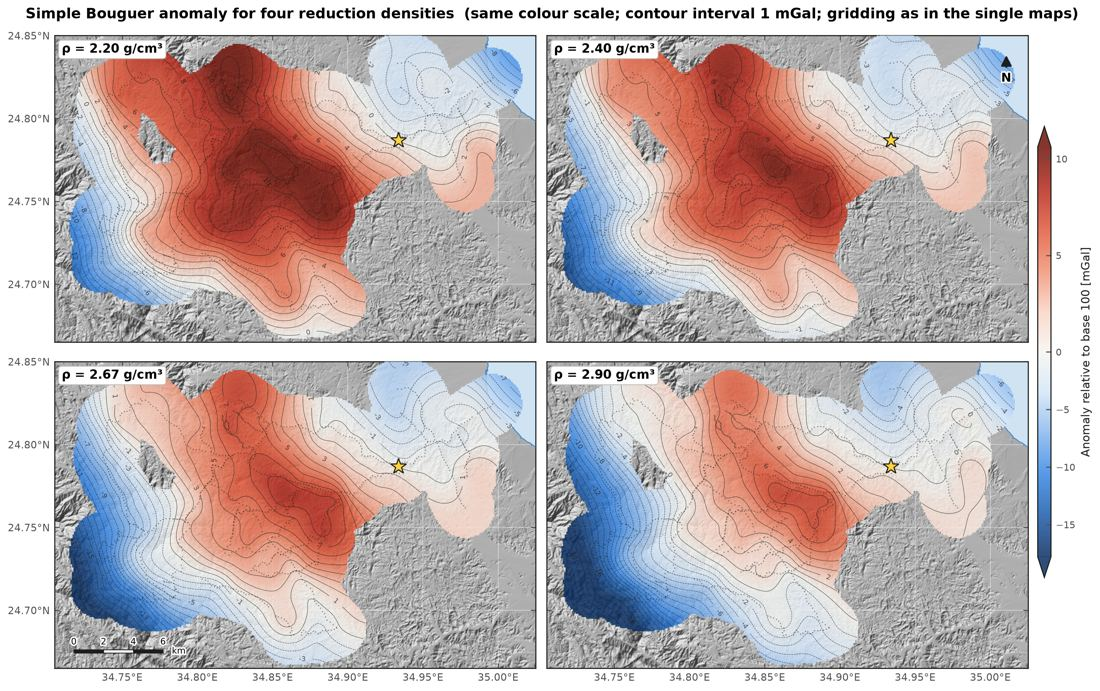

In [18]:
show_figures(os.path.join(OUT_DIR, "maps"))

### Nettleton density analysis (summary)

`nettleton_summary_profiles.png`

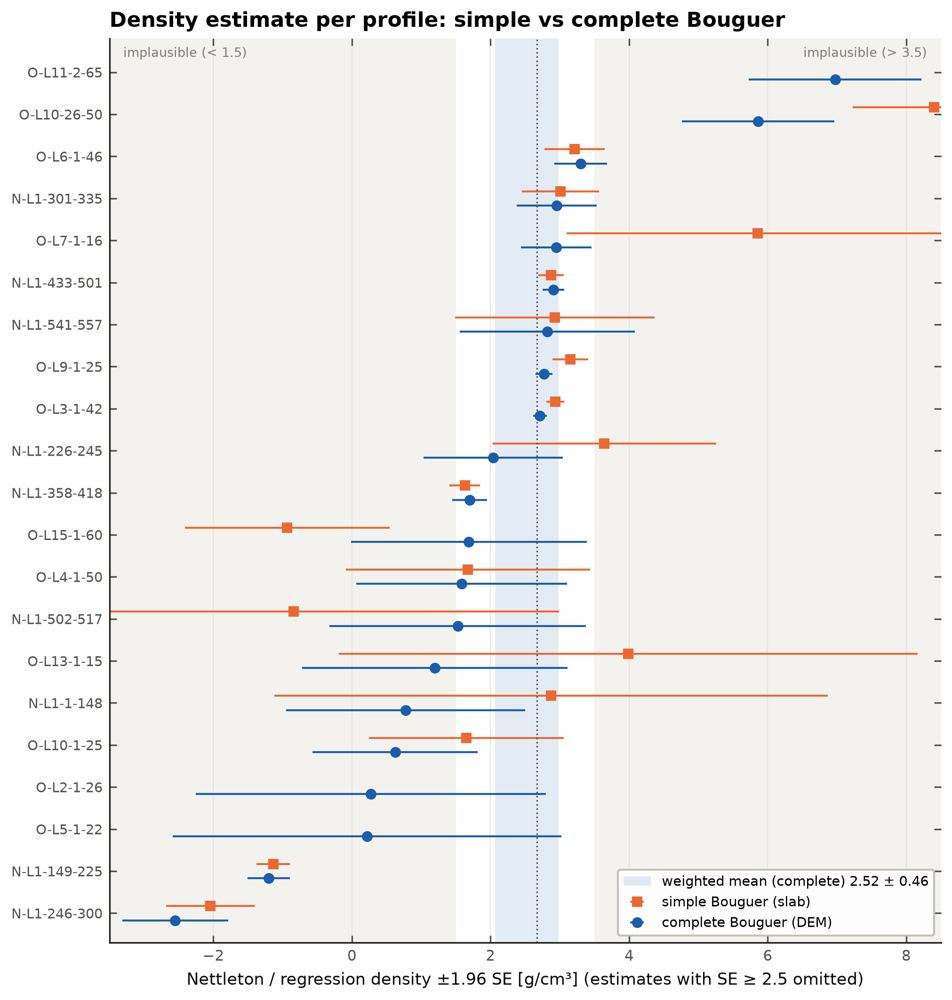

`nettleton_windows_map.png`

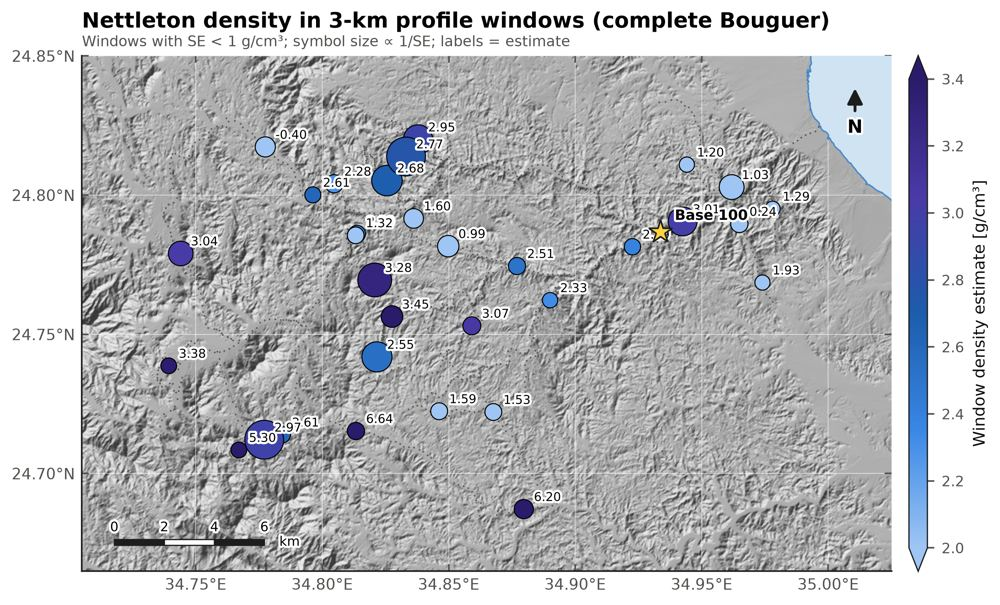

`nettleton_windows_histogram.png`

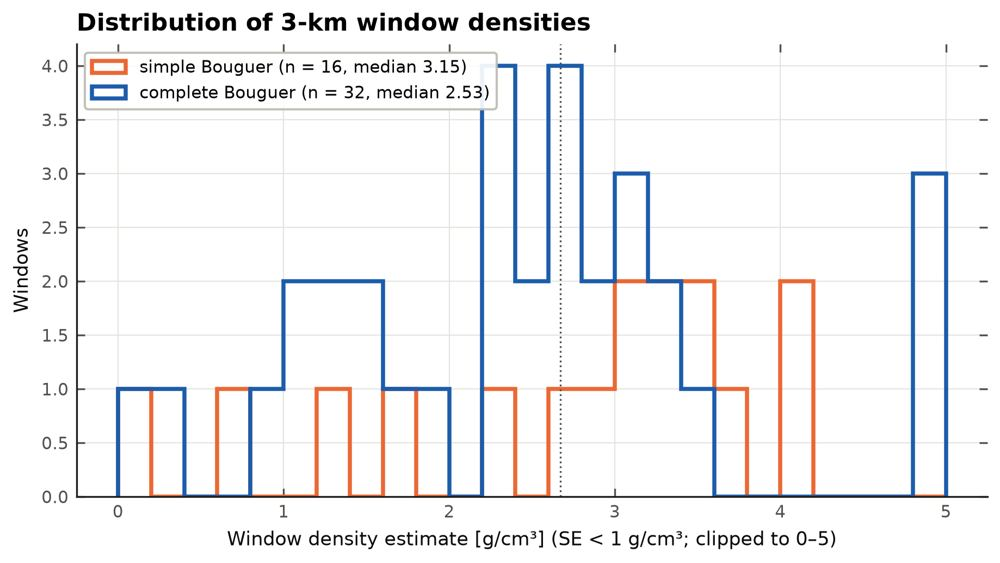

In [19]:
for f in ("nettleton_summary_profiles.png", "nettleton_windows_map.png", "nettleton_windows_histogram.png"):
    show_figure(os.path.join(OUT_DIR, "nettleton", f), max_px=1000)

## Results

| Folder in `outputs/` | Content |
|---|---|
| `deliverables/` | `Wadi_Ghadir_Gravity_Results.xlsx`, `Wadi_Ghadir_Final_Stations.csv / .geojson / .kml` |
| `tables/` | processing tables 01–23 (every intermediate result) |
| `maps/`, `grids/` | publication maps; grids as NetCDF and XYZ CSV |
| `figures/`, `nettleton/` | QC figures; density sheets per profile |
| `summary.json` | key numbers of the run |

Recommended product: **complete Bouguer anomaly relative to base 100, ρ = 2.67 g/cm³** (`CB_rel_2.67_mGal`),
with the density panels showing the sensitivity to ρ. See the report for interpretation limits.

*Prepared by Dr. Mohamed Sobh, LIAG.*